In [1]:
import seaborn as sns

from fau_colors import register_cmaps
register_cmaps()

sns.set_palette("faculties_light")

# Set presentation context
sns.set_context("notebook", font_scale=1)
sns.set_style("whitegrid")
sns.set_style("ticks")
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
import os 
os.chdir('../')

trial=1, Work=Negative: 0.10
trial=1, Work=Positive: 0.16
trial=1, Work=Overall: 0.13
trial=2, Work=Negative: 0.08
trial=2, Work=Positive: 0.12
trial=2, Work=Overall: 0.09
trial=3, Work=Negative: 0.06
trial=3, Work=Positive: 0.18
trial=3, Work=Overall: 0.09
trial=4, Work=Negative: 0.03
trial=4, Work=Positive: 0.11
trial=4, Work=Overall: 0.05
trial=5, Work=Negative: 0.09
trial=5, Work=Positive: 0.07
trial=5, Work=Overall: 0.08
trial=6, Work=Negative: 0.12
trial=6, Work=Positive: 0.08
trial=6, Work=Overall: 0.09
Work=Negative: 0.080
Work=Positive: 0.122
Work=Overall: 0.091
trial=1: 0.130
trial=2: 0.096
trial=3: 0.112
trial=4: 0.063
trial=5: 0.080
trial=6: 0.096
Overall: 0.098


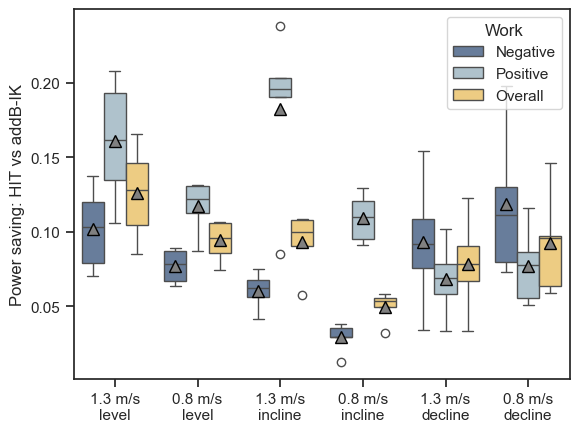

In [114]:
# Power plots 
df = pd.DataFrame(columns=['participant', 'trial', 'Work', 'MSK Model', 'value'])
df1 = pd.DataFrame(columns=['participant', 'trial', 'Work', 'value'])
participants = ['P01','P02','P03','P04','P05','P06']
mass_list = [72.31, 73.35, 64.49, 89.36, 87.63,44.91]
for participant,mass in zip(participants, mass_list):
    for trial in [1,2,3,4,5,6]:
        if (participant == 'P06' and trial == 5): continue
        if (participant == 'P01' and trial > 2): continue
        ik_data = pd.read_csv(f"results/{participant}/gait/addB-ignore_phys/IK/Trial{trial}_filtered.mot", sep='\t', skiprows=10)
        id1 = pd.read_csv(f"results/{participant}/gait/ID_results/Trial_{trial}-SBP-HIT_body.sto", sep='\t', skiprows=6)
        id2 = pd.read_csv(f"results/{participant}/gait/ID_results//Trial_{trial}.sto", sep='\t', skiprows=6)
        pow1 = np.zeros(ik_data.shape)
        pow2 = np.zeros(ik_data.shape)
        for i, col_a in enumerate(ik_data.columns):
            ik_data.loc[:,col_a] = np.gradient(ik_data[col_a]) * 100
            if col_a in ['time', 'Time', 'Frame#'] or col_a.startswith('pelvis'):
                continue
            try:
                pow1[:,i] = id1[col_a+'_moment'] * ik_data[col_a] / len(ik_data)
                pow2[:,i] = id2[col_a+'_moment'] * ik_data[col_a] / len(ik_data)  
            except:
                pow1[:,i] = id1[col_a+'_force'] * ik_data[col_a] / len(ik_data) 
                pow2[:,i] = id2[col_a+'_force'] * ik_data[col_a] / len(ik_data)
                print(col_a)
        df.loc[len(df)] = [participant, trial, 'pos_ih', 'SIPP',np.sum(pow1[pow1>0])/mass]
        df.loc[len(df)] = [participant, trial, 'neg_ih', 'SIPP', -np.sum(pow1[pow1<0])/mass]
        df.loc[len(df)] = [participant, trial, 'pos_addb', 'Generic', np.sum(pow2[pow2>0])/mass]
        df.loc[len(df)] = [participant, trial, 'neg_addb','Generic', -np.sum(pow2[pow2<0])/mass]
        df1.loc[len(df1)] = [participant, trial, 'Negative', -1+np.sum(pow2[pow2>0])/np.sum(pow1[pow1>0])]
        df1.loc[len(df1)] = [participant, trial, 'Positive', -1+np.sum(pow2[pow2<0])/np.sum(pow1[pow1<0])]
        df.loc[len(df)] = [participant, trial, 'total_ih','SIPP', np.sum(np.abs(pow1))/mass]
        df.loc[len(df)] = [participant, trial, 'total_addb','Generic', np.sum(np.abs(pow2))/mass]
        df1.loc[len(df1)] = [participant, trial, 'Overall', -1+np.sum(np.abs(pow2))/np.sum(np.abs(pow1))]
        #break

df2 = df1.copy()
x = 'trial'
hue = 'Work'
sns.boxplot(df2, x=x, y='value', hue=hue,showmeans=True,meanprops={'marker':'^','markerfacecolor':'grey','markeredgecolor':'black','markersize':'8'})
# Y grid
# Plot the mean for every column
# Rename the xticks
plt.xticks(labels=["1.3 m/s\nlevel", "0.8 m/s\nlevel", "1.3 m/s\nincline", "0.8 m/s\nincline", "1.3 m/s\ndecline", "0.8 m/s\ndecline"], ticks=[0, 1, 2, 3, 4, 5])
plt.ylabel('Power saving: HIT vs addB-IK')
#plt.xlabel('Trial')
# print the mean for every column x and per x and hue
# Get a list of unique values in the column
for value_ in df2[x].unique():
    for hue_ in df2[hue].unique():
        print(f'{x}={value_}, {hue}={hue_}: {df2[(df2[x] == value_) & (df2[hue] == hue_)].value.mean():.2f}')
for hue_ in df2[hue].unique():
    print(f'{hue}={hue_}: {df2[df2[hue] == hue_].value.mean():.3f}')
for value_ in df2[x].unique():
    print(f'{x}={value_}: {df2[df2[x] == value_].value.mean():.3f}')
# Print the mean for every column
print(f'Overall: {df2.value.mean():.3f}')
# Remove the x title
plt.xlabel('')

# save as pdf
os.makedirs('plots', exist_ok=True)
plt.savefig('plots/power_saving.pdf', bbox_inches='tight')


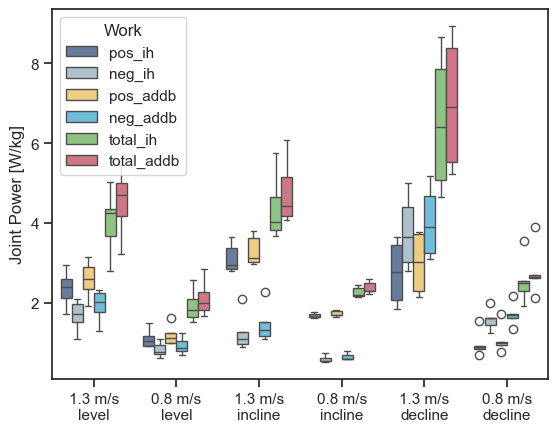

In [119]:

plt.figure()
df3 = df.copy()
x = 'trial'
hue = 'MSK Model'
hue = 'Work'
sns.boxplot(df3, x=x, y='value', hue=hue)#,showmeans=True,meanprops={'marker':'^','markerfacecolor':'grey','markeredgecolor':'black','markersize':'8'})
plt.xticks(labels=["1.3 m/s\nlevel", "0.8 m/s\nlevel", "1.3 m/s\nincline", "0.8 m/s\nincline", "1.3 m/s\ndecline", "0.8 m/s\ndecline"], ticks=[0, 1, 2, 3, 4, 5])
plt.ylabel('Joint Power [W/kg]')
plt.xlabel('')
plt.savefig('plots/power_per_model.pdf', bbox_inches='tight')

x_order = df3[x].unique()
hue_order = df3[hue].unique()
x_offsets = {label: idx for idx, label in enumerate(x_order)}

# Calculate the offset for hue categories (Seaborn adds small offsets to separate hue boxes)
hue_offsets = {-0.2, 0.2}  # Approx offsets for 2 hue levels
hue_offsets = dict(zip(hue_order, sorted(hue_offsets)))

# Group the data by ID and trial to find paired points
for (trial_val, p), group in df3.groupby(['trial','participant']):
    if group.shape[0] == 2:  # Make sure we have both hues
        x_base = x_offsets[trial_val]
        x1 = x_base + hue_offsets[group.iloc[0][hue]]
        x2 = x_base + hue_offsets[group.iloc[1][hue]]
        y1 = group.iloc[0]['value']
        y2 = group.iloc[1]['value']
        plt.plot([x1, x2], [y1, y2], color='grey', alpha=0.66)

plt.show()
# Print the mean for every column

In [116]:
### Explore what went wrong with P01
id1 = pd.read_csv(f"results/P01/gait/ID_results/Trial_{2}-SBP-HIT_body.sto", sep='\t', skiprows=6)

,time,pelvis_tilt_moment,pelvis_list_moment,pelvis_rotation_moment,pelvis_tx_force,pelvis_ty_force,pelvis_tz_force,hip_flexion_r_moment,hip_adduction_r_moment,hip_rotation_r_moment,...,subtalar_angle_r_moment,subtalar_angle_l_moment,pro_sup_r_moment,pro_sup_l_moment,mtp_angle_r_moment,mtp_angle_l_moment,wrist_flex_r_moment,wrist_dev_r_moment,wrist_flex_l_moment,wrist_dev_l_moment
0,0.01,-6.463344,25.697745,2.310275,-25.813964,11.119856,14.182086,-12.422031,-40.847888,5.245593,...,9.699607,-1.743930,-0.079043,-0.078489,-0.007753,0.003137,-0.050684,-0.322306,-0.115667,-0.288284
1,0.02,-6.873187,26.117618,3.133556,-26.797755,13.277429,12.886073,-12.602620,-39.445442,5.280883,...,9.764826,-1.434754,-0.078053,-0.077240,-0.007737,0.003151,-0.047027,-0.319815,-0.113766,-0.291446
2,0.03,-6.789966,26.275012,3.433910,-27.420300,13.606531,10.787908,-12.752134,-38.308005,5.193542,...,9.761247,-1.550789,-0.073570,-0.072583,-0.007685,0.003188,-0.029827,-0.308104,-0.106605,-0.299258
3,0.04,-7.228913,26.882215,3.116178,-21.444570,17.141732,9.937619,-12.638912,-37.459117,4.886962,...,9.697303,-1.931073,-0.071047,-0.076806,-0.007713,0.003190,-0.020914,-0.294254,-0.116263,-0.298542
4,0.05,-7.583136,27.464601,2.756575,-16.221086,21.288368,10.434075,-12.541175,-36.759795,4.623838,...,9.637928,-2.312100,-0.071375,-0.081583,-0.007753,0.003193,-0.024033,-0.285891,-0.124854,-0.295533
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
29992,299.93,0.545014,30.542745,4.799903,-6.012623,15.506980,-4.849733,9.732401,-43.815205,6.257556,...,29.314107,1.465586,-0.009199,-0.017291,-0.007400,0.004965,0.057690,-0.012142,-0.004689,-0.165523
29993,299.94,5.822128,28.227587,6.317635,-17.931907,16.764433,-3.257809,9.178556,-42.605135,7.632231,...,30.476866,2.549258,-0.005891,-0.014393,-0.007356,0.005225,0.041278,-0.018312,-0.007311,-0.155232
29994,299.95,0.875622,22.588213,9.782941,-39.189983,-7.875027,5.327109,5.465393,-41.739376,10.046405,...,32.130361,3.347034,-0.010400,-0.009643,-0.007475,0.005951,0.018240,-0.043631,-0.013617,-0.123870
29995,299.96,-21.403075,14.689993,15.010146,-77.758902,-87.688617,31.500694,-3.873006,-41.074386,13.985634,...,34.652409,1.289852,-0.025773,-0.008333,-0.007951,0.007285,0.009006,-0.117232,-0.033512,-0.052101


In [112]:
collfunc = lambda x: np.mean(np.abs(x))
pipelines = [['HIT', 'body']]#, ['InsideHumans', 'skin']] #['HIT', 'scan']]
participants = ['P01','P02','P03','P04','P05','P06']
mass_list = [72.31, 73.35, 64.49, 89.36, 87.63,44.91]
result_df = pd.DataFrame(columns=['participant', 'trial','MSK Model', 'dimension', 'value','value_rel'])
for participant,mass in zip(participants, mass_list):
    for trial in range(1,7):
        if (participant == 'P06' and trial == 5): continue
        if (participant == 'P01' and trial > 2): continue
        for pipeline in pipelines:
            name, model = pipeline
            name2 = name+model
            id1 = pd.read_csv(f"results/{participant}/gait/ID_results/Trial_{trial}-SBP-{name}_{model}.sto", sep='\t', skiprows=6)
            #try:
            #    id3 = pd.read_csv(f"results/{participant}/gait/ID_results/Trial{trial}_generic_male_body.sto", sep='\t', skiprows=6)
            #except:
            #    id3 = pd.read_csv(f"results/{participant}/gait/ID_results/Trial{trial}_generic_female_body.sto", sep='\t', skiprows=6)
            id2 = pd.read_csv(f"results/{participant}/gait/ID_results/Trial_{trial}.sto", sep='\t', skiprows=6)
            for dim in ['pelvis_tx_force', 'pelvis_ty_force', 'pelvis_tz_force', 'pelvis_tilt_moment', 'pelvis_list_moment', 'pelvis_rotation_moment']:
                result_df.loc[len(result_df)] = [participant, trial, "SIPP", dim, collfunc(id1[dim])/mass/9.81, (collfunc(id2[dim])-collfunc(id1[dim]))/collfunc(id2[dim])]
            #result_df.loc[len(result_df)] = [participant, trial, name, 'f_norm', np.mean(np.linalg.norm([id1['pelvis_tx_force'], id1['pelvis_ty_force'], id1['pelvis_tz_force']], axis=0))/mass/9.81, 0]
            #result_df.loc[len(result_df)] = [participant, trial, name, 'm_norm', np.mean(np.linalg.norm([id1['pelvis_tilt_moment'], id1['pelvis_list_moment'], id1['pelvis_rotation_moment']], axis=0))/mass/9.81, 0]
        for dim in ['pelvis_tx_force', 'pelvis_ty_force', 'pelvis_tz_force', 'pelvis_tilt_moment', 'pelvis_list_moment', 'pelvis_rotation_moment']:
            result_df.loc[len(result_df)] = [participant, trial, 'Generic', dim, collfunc(id2[dim])/mass/9.81, 0]
        #result_df.loc[len(result_df)] = [participant, trial, 'addB-IK', 'f_norm', np.mean(np.linalg.norm([id2[dim] for dim in ['pelvis_tx_force', 'pelvis_ty_force', 'pelvis_tz_force']], axis=0))/mass/9.81, 0]
        #result_df.loc[len(result_df)] = [participant, trial, 'addB-IK', 'm_norm', np.mean(np.linalg.norm([id2[dim] for dim in ['pelvis_tilt_moment', 'pelvis_list_moment', 'pelvis_rotation_moment']], axis=0))/mass/9.81, 0]
result_df

,participant,trial,MSK Model,dimension,value,value_rel
0,P01,1,SIPP,pelvis_tx_force,0.043374,0.292337
1,P01,1,SIPP,pelvis_ty_force,0.032267,0.113500
2,P01,1,SIPP,pelvis_tz_force,0.032930,-0.008811
3,P01,1,SIPP,pelvis_tilt_moment,0.030070,0.360904
4,P01,1,SIPP,pelvis_list_moment,0.034984,-0.206635
...,...,...,...,...,...,...
367,P06,6,Generic,pelvis_ty_force,0.030870,0.000000
368,P06,6,Generic,pelvis_tz_force,0.030002,0.000000
369,P06,6,Generic,pelvis_tilt_moment,0.022743,0.000000
370,P06,6,Generic,pelvis_list_moment,0.015856,0.000000


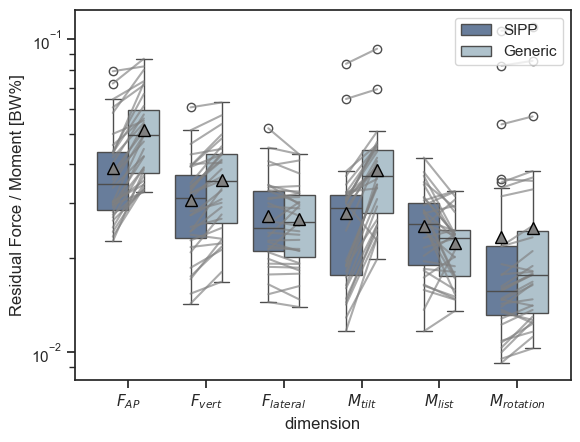

In [113]:
import seaborn as sns
hue = 'MSK Model'
x = 'dimension'
sns.boxplot(x=x, y='value', data=result_df, hue=hue,showmeans = True,meanprops={'marker':'^','markerfacecolor':'grey','markeredgecolor':'black','markersize':'8'})
# Make the x labels vertical
plt.ylabel('Residual Force / Moment [BW%]')
# out the legend to the top right
plt.legend(loc='upper right')
# rename the x ticks
plt.xticks(labels=["$F_{AP}$", "$F_{vert}$", "$F_{lateral}$", "$M_{tilt}$", "$M_{list}$", "$M_{rotation}$"], ticks=[0, 1, 2, 3, 4, 5])
# Save the plot
x_order = result_df[x].unique()
hue_order = result_df[hue].unique()
x_offsets = {label: idx for idx, label in enumerate(x_order)}

# Calculate the offset for hue categories (Seaborn adds small offsets to separate hue boxes)
hue_offsets = {-0.2, 0.2}  # Approx offsets for 2 hue levels
hue_offsets = dict(zip(hue_order, sorted(hue_offsets)))
plt.yscale('log')
# Group the data by ID and trial to find paired points
for (trial_val, p, d), group in result_df.groupby(['trial','participant','dimension']):
    if group.shape[0] == 2:  # Make sure we have both hues
        x_base = x_offsets[d]
        x1 = x_base + hue_offsets[group.iloc[0][hue]]
        x2 = x_base + hue_offsets[group.iloc[1][hue]]
        y1 = group.iloc[0]['value']
        y2 = group.iloc[1]['value']
        plt.plot([x1, x2], [y1, y2], color='grey', alpha=0.66)

plt.savefig('plots/force_moment.pdf', bbox_inches='tight')



In [106]:
x_offsets

{'pelvis_tx_force': 0,
 'pelvis_ty_force': 1,
 'pelvis_tz_force': 2,
 'pelvis_tilt_moment': 3,
 'pelvis_list_moment': 4,
 'pelvis_rotation_moment': 5}

In [5]:
HIT = []
generic = []
no_phys = []
for p in ['P02','P04','P05','P06']:

    hit_path = f"/Users/markusgambietz/PhD/01_Python_Projects/mrigait_empkins/results/{p}/gait/addB-with_phys/HIT/IK"
    generic_path = f"/Users/markusgambietz/PhD/01_Python_Projects/mrigait_empkins/results/{p}/gait/addB-with_phys/generic/IK"
    no_phys_path = f"/Users/markusgambietz/PhD/01_Python_Projects/mrigait_empkins/results/{p}/gait/addB-ignore_phys/IK"
    # for every file that ends with .sto in the HIT folder

    for file in os.listdir(hit_path):
        if file.endswith(".csv"):
            hit = pd.read_csv(os.path.join(hit_path, file))
            HIT.append(np.array(hit.iloc[:,1:]).mean())
    for file in os.listdir(generic_path):
        if file.endswith(".csv"):
            gen = pd.read_csv(os.path.join(generic_path, file))
            generic.append(np.array(gen.iloc[:,1:]).mean())
    for file in os.listdir(no_phys_path):
            if file.endswith(".csv"):
                no = pd.read_csv(os.path.join(no_phys_path, file))
                no_phys.append(np.array(no.iloc[:,1:]).mean())
import seaborn as sns
import matplotlib.pyplot as plt
# Create a dataframe


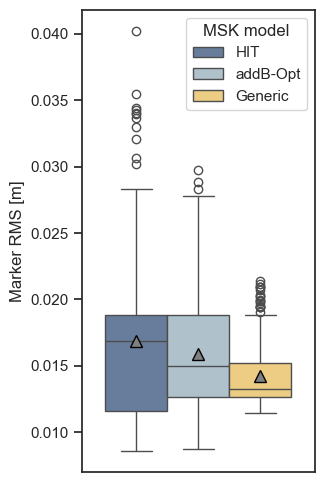

In [6]:
hit = pd.DataFrame(HIT)
gen = pd.DataFrame(generic)
no = pd.DataFrame(no_phys)
hit['MSK model'] = 'HIT'
gen['MSK model'] = 'addB-Opt'
no['MSK model'] = 'Generic'
df = pd.concat([hit, gen, no])
df = df.melt(id_vars='MSK model')

# Make the figure narrower
plt.figure(figsize=(3,6))
sns.boxplot(hue='MSK model', y='value', data=df,showmeans = True,meanprops={'marker':'^','markerfacecolor':'grey','markeredgecolor':'black','markersize':'8'})
plt.ylabel('Marker RMS [m]')
# Remove the tick in the x axis
plt.xticks([])

# Save the plot
plt.savefig('plots/markerrms.pdf', bbox_inches='tight')

In [7]:
HIT = {
    "pelvis_tx_force": [],
    "pelvis_ty_force": [],
    "pelvis_tz_force": [],
    "pelvis_tilt_moment": [],
    "pelvis_list_moment": [],
    "pelvis_rotation_moment": []
}
generic = {
    "pelvis_tx_force": [],
    "pelvis_ty_force": [],
    "pelvis_tz_force": [],
    "pelvis_tilt_moment": [],
    "pelvis_list_moment": [],
    "pelvis_rotation_moment": []
}
for p, mass in zip(['P02','P04','P05','P06'],mass_list):

    hit_path = f"/Users/markusgambietz/PhD/01_Python_Projects/mrigait_empkins/results/{p}/gait/addB-with_phys/HIT/ID"
    generic_path = f"/Users/markusgambietz/PhD/01_Python_Projects/mrigait_empkins/results/{p}/gait/addB-with_phys/generic/ID"
    # for every file that ends with .sto in the HIT folder

    for file in os.listdir(hit_path):
        if file.endswith(".sto"):
            hit = pd.read_csv(os.path.join(hit_path, file), sep='\t', skiprows=10)
            for key in HIT.keys():
                HIT[key].append(np.abs(hit[key]).mean()/mass/9.81)
    for file in os.listdir(generic_path):
        if file.endswith(".sto"):
            gen = pd.read_csv(os.path.join(generic_path, file), sep='\t', skiprows=10)
            for key in generic.keys():
                generic[key].append(np.abs(gen[key]).mean()/mass/9.81)


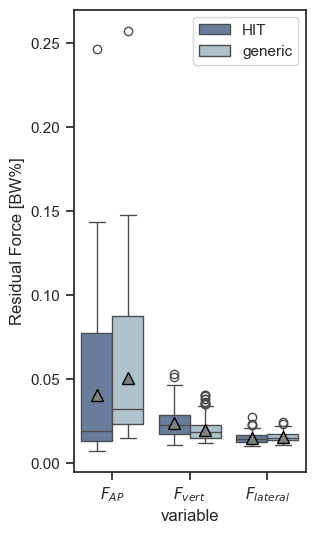

In [8]:
hit = pd.DataFrame(HIT)
gen = pd.DataFrame(generic)
gen = gen.iloc[:,3:]
hit = hit.iloc[:,3:]
hit['pipeline'] = 'HIT'
gen['pipeline'] = 'generic'
df = pd.concat([hit, gen])
df = df.melt(id_vars='pipeline')
plt.figure(figsize=(3,6))

sns.boxplot(x='variable', y='value', data=df, hue='pipeline', showmeans = True,meanprops={'marker':'^','markerfacecolor':'grey','markeredgecolor':'black','markersize':'8'})

plt.ylabel('Residual Force [BW%]')
# out the legend to the top right
plt.legend(loc='upper right')
# rename the x ticks
plt.xticks(labels=["$F_{AP}$", "$F_{vert}$", "$F_{lateral}$"], ticks=[0, 1, 2])
# Save the plot
plt.savefig('plots/force.pdf', bbox_inches='tight')

In [65]:
hit = pd.DataFrame(HIT)
gen = pd.DataFrame(generic)
gen = gen.iloc[:,:3]
hit = hit.iloc[:,:3]
hit['pipeline'] = 'HIT'
gen['pipeline'] = 'generic'
df = pd.concat([hit, gen])
df = df.melt(id_vars='pipeline')
plt.figure(figsize=(3,6))

sns.boxplot(x='variable', y='value', data=df, hue='pipeline', showmeans = True,meanprops={'marker':'^','markerfacecolor':'grey','markeredgecolor':'black','markersize':'8'})

plt.ylabel('Residual Moment [BW%]')
# out the legend to the top right
plt.legend(loc='upper right')
# rename the x ticks
plt.xticks(labels=["\textbf{M}_{tilt}$", "$M_{list}$", "$M_{rotation}$"], ticks=[0, 1, 2])
# Save the plot
plt.savefig('plots/residual_moment.pdf', bbox_inches='tight')

ValueError: All arrays must be of the same length

In [39]:
# Compare all powers: HIT-IK vs addB-IK, HIT-IK vs addB-ID, HIT-ID vs addB-ID
addB_ik = {
    "Positive": [],
    "Negative": [],
    "Overall": [],
    "Trial1": [],
    "Trial2":  [],
    "Trial3": [],
    "Trial4": [],
    "Trial5": [],
    "Trial6": []
}
HIT = {
    "Positive": [],
    "Negative": [],
    "Overall": [],
    "Trial1": [],
    "Trial2":  [],
    "Trial3": [],
    "Trial4": [],
    "Trial5": [],
    "Trial6": []
}
addB_id = {
    "Positive": [],
    "Negative": [],
    "Overall": [],
    "Trial1": [],
    "Trial2":  [],
    "Trial3": [],
    "Trial4": [],
    "Trial5": [],
    "Trial6": []
}
HIT_addB_id = {
    "Positive": [],
    "Negative": [],
    "Overall": [],
    "Trial1": [],
    "Trial2":  [],
    "Trial3": [],
    "Trial4": [],
    "Trial5": [],
    "Trial6": []
}
for p in ['P02','P04','P05','P06']:
    hit_path_id = f"/Users/markusgambietz/PhD/01_Python_Projects/mrigait_empkins/results/{p}/gait/addB-with_phys/HIT/ID"
    generic_path_id = f"/Users/markusgambietz/PhD/01_Python_Projects/mrigait_empkins/results/{p}/gait/addB-with_phys/generic/ID"
    hit_path_ik = f"/Users/markusgambietz/PhD/01_Python_Projects/mrigait_empkins/results/{p}/gait/ID_results"
    ik_data_path = f"/Users/markusgambietz/PhD/01_Python_Projects/mrigait_empkins/results/{p}/gait/addB-ignore_phys/IK"
    for trial in range(1,7):
        if p == "P03" or (p == 'P06' and trial == 5) or (p == 'P01' and trial > 2) or (p == 'P03' and trial == 2):
            continue
        ik_data = pd.read_csv(os.path.join(ik_data_path, f"Trial{trial}_filtered.mot"), sep='\t', skiprows=10)
        id1 = pd.read_csv(os.path.join(hit_path_ik, f"Trial{trial}_HIT_body.sto"), sep='\t', skiprows=6)
        id2 = pd.read_csv(os.path.join(hit_path_ik, f"Trial{trial}_ignore_physics.sto"), sep='\t', skiprows=6)
        pow1 = np.zeros(ik_data.shape)
        pow2 = np.zeros(ik_data.shape)
        for i, col_a in enumerate(ik_data.columns):
            ik_data.loc[:,col_a] = np.gradient(ik_data[col_a]) * 100
            if col_a in ['time', 'Time', 'Frame#'] or col_a.startswith('pelvis'):
                continue
            try:
                pow1[:,i] = id1[col_a+'_moment'] * ik_data[col_a] / len(ik_data)
                pow2[:,i] = id2[col_a+'_moment'] * ik_data[col_a] / len(ik_data)  
            except:
                pow1[:,i] = id1[col_a+'_force'] * ik_data[col_a] / len(ik_data) 
                pow2[:,i] = id2[col_a+'_force'] * ik_data[col_a] / len(ik_data)
                print(col_a)
        #df.loc[len(df)] = [participant, trial, 'pos_ih', np.sum(pow1[pow1>0])/mass]
        #df.loc[len(df)] = [participant, trial, 'neg_ih', -np.sum(pow1[pow1<0])/mass]
        #df.loc[len(df)] = [participant, trial, 'pos_addb', np.sum(pow2[pow2>0])/mass]
        #df.loc[len(df)] = [participant, trial, 'neg_addb', -np.sum(pow2[pow2<0])/mass]
        HIT['Positive'].append(np.sum(pow1[pow1>0])/mass)
        HIT['Negative'].append(-np.sum(pow1[pow1<0])/mass)
        HIT['Overall'].append(np.sum(np.abs(pow1))/mass)
        addB_ik['Positive'].append(np.sum(pow2[pow2>0])/mass)
        addB_ik['Negative'].append(-np.sum(pow2[pow2<0])/mass)
        addB_ik['Overall'].append(np.sum(np.abs(pow2))/mass)
        HIT[f"Trial{trial}"].append(np.sum(np.abs(pow1))/mass)
        addB_ik[f"Trial{trial}"].append(np.sum(np.abs(pow2))/mass)

    hit_path = f"/Users/markusgambietz/PhD/01_Python_Projects/mrigait_empkins/results/{p}/gait/addB-with_phys/HIT/ID"
    generic_path = f"/Users/markusgambietz/PhD/01_Python_Projects/mrigait_empkins/results/{p}/gait/addB-with_phys/generic/ID"
    # for every file that ends with .sto in the HIT folder
ik_data_0, id1_0, id2_0 = ik_data, id1, id2

In [40]:
for p in ['P02','P04','P05','P06']:
    for file in os.listdir(hit_path):
        if True:
            if file.endswith(".sto"):
                ik_file = file.replace('.sto', '.mot').replace('ID', 'IK').replace('id','ik')
                ik_path = hit_path.replace('ID', 'IK')
                ik_data = pd.read_csv(os.path.join(ik_path, ik_file), sep='\t', skiprows=10)
                hit = pd.read_csv(os.path.join(hit_path, file), sep='\t', skiprows=10)
                pow = np.zeros(hit.shape)
                for i, col_a in enumerate(ik_data.columns):
                    hit.loc[:,col_a] = np.gradient(ik_data[col_a]) * 100
                    if col_a in ['time', 'Time', 'Frame#'] or col_a.startswith('pelvis'):
                        continue
                    try:
                        pow[:,i] = hit[col_a+'_moment'] * hit[col_a] / len(hit)
                    except:
                        pow[:,i] = hit[col_a+'_force'] * hit[col_a] / len(hit)
                        print(col_a)
                #df.loc[len(df)] = [participant, trial, 'pos_ih', np.sum(pow1[pow1>0])/mass]
                HIT_addB_id['Positive'].append(np.sum(pow[pow>0])/mass)
                HIT_addB_id['Negative'].append(-np.sum(pow[pow<0])/mass)
                HIT_addB_id['Overall'].append(np.sum(np.abs(pow))/mass)
                trial = file.split('rial')[1][0]
                HIT_addB_id[f"Trial{trial}"].append(np.sum(np.abs(pow))/mass)
        #except:
        #    print(file)
    for file in os.listdir(generic_path):
        try:
            if file.endswith(".sto"):
                ik_file = file.replace('.sto', '.mot').replace('ID', 'IK').replace('id','ik')
                ik_path = hit_path.replace('ID', 'IK')
                ik_data = pd.read_csv(os.path.join(ik_path, ik_file), sep='\t', skiprows=10)
                gen = pd.read_csv(os.path.join(generic_path, file), sep='\t', skiprows=10)
                pow = np.zeros(gen.shape)
                for i, col_a in enumerate(ik_data.columns):
                    gen.loc[:,col_a] = np.gradient(ik_data[col_a]) * 100
                    if col_a in ['time', 'Time', 'Frame#'] or col_a.startswith('pelvis'):
                        continue
                    try:
                        pow[:,i] = gen[col_a+'_moment'] * gen[col_a] / len(gen)
                    except:
                        pow[:,i] = gen[col_a+'_force'] * gen[col_a] / len(gen)
                        print(col_a)
                addB_id['Positive'].append(np.sum(pow[pow>0])/mass)
                addB_id['Negative'].append(-np.sum(pow[pow<0])/mass)
                addB_id['Overall'].append(np.sum(np.abs(pow))/mass)
                trial = file.split('rial')[1][0]
                addB_id[f"Trial{trial}"].append(np.sum(np.abs(pow))/mass)

        except:
            print(file)

(220.01, 239.999)

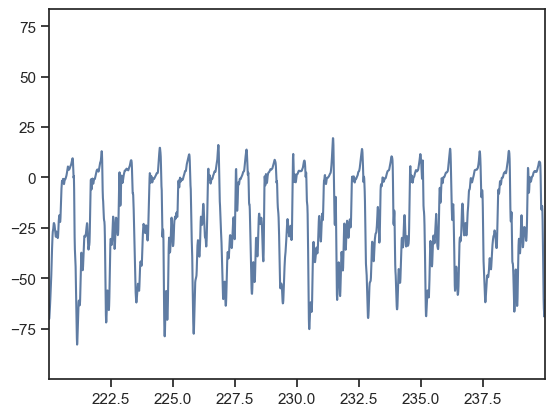

In [77]:
plt.plot(ik_data_0.time, id2.knee_angle_r_moment)
#plt.plot(ik_data.time, gen.knee_angle_r_moment)
plt.xlim(ik_data.time[0], ik_data.time.max())

In [63]:
ik_data_0.shape

(29997, 38)

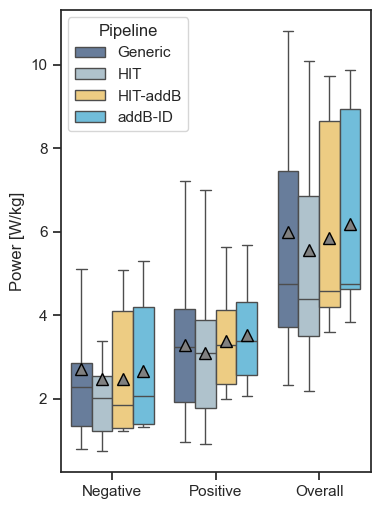

In [ ]:
addB_ik_ = pd.DataFrame({key:addB_ik[key] for key in ['Negative','Positive','Overall']})
HIT_ = pd.DataFrame({key:HIT[key] for key in ['Negative','Positive','Overall']})
HIT_addB_id_ =pd.DataFrame({key:HIT_addB_id[key] for key in ['Negative','Positive','Overall']})
addB_id_ = pd.DataFrame({key:addB_id[key] for key in ['Negative','Positive','Overall']})
addB_ik_['Pipeline'] = 'Generic'
HIT_['Pipeline'] = 'HIT'
HIT_addB_id_['Pipeline'] = 'HIT-addB'
addB_id_['Pipeline'] = 'addB-ID'

df = pd.concat([addB_ik_, HIT_, HIT_addB_id_, addB_id_])
df = df.melt(id_vars='Pipeline')
plt.figure(figsize=(4,6))

# Make the plot but use multiple colors
sns.boxplot(y='value', data=df, x="variable", hue='Pipeline', showfliers=False, showmeans = True,meanprops={'marker':'^','markerfacecolor':'grey','markeredgecolor':'black','markersize':'8'})
plt.xlabel('')
plt.ylabel('Power [W/kg]')
# save as pdf
plt.savefig('plots/power_comparison.pdf', bbox_inches='tight')

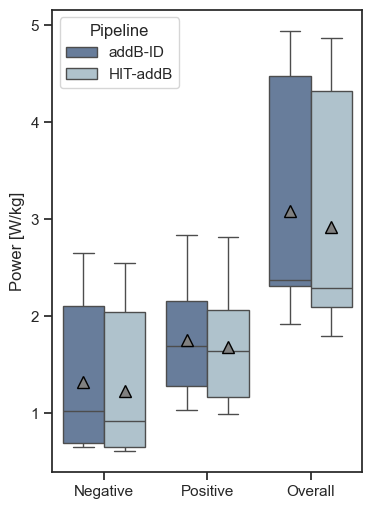

In [42]:
addB_ik_ = pd.DataFrame({key:addB_ik[key] for key in ['Negative','Positive','Overall']})
HIT_ = pd.DataFrame({key:HIT[key] for key in ['Negative','Positive','Overall']})
HIT_addB_id_ =pd.DataFrame({key:HIT_addB_id[key] for key in ['Negative','Positive','Overall']})
addB_id_ = pd.DataFrame({key:addB_id[key] for key in ['Negative','Positive','Overall']})
addB_ik_['Pipeline'] = 'Generic'
HIT_['Pipeline'] = 'HIT'
HIT_addB_id_['Pipeline'] = 'HIT-addB'
addB_id_['Pipeline'] = 'addB-ID'
df = pd.concat([addB_id_, HIT_addB_id_])
df = df.melt(id_vars='Pipeline')
# Make the plot but use multiple colors
plt.figure(figsize=(4,6))

sns.boxplot(y='value', data=df, x="variable", hue='Pipeline', showfliers=False, showmeans = True,meanprops={'marker':'^','markerfacecolor':'grey','markeredgecolor':'black','markersize':'8'})
plt.xlabel('')
plt.ylabel('Power [W/kg]')
# save as pdf
plt.savefig('plots/power_comparison_id.pdf', bbox_inches='tight')

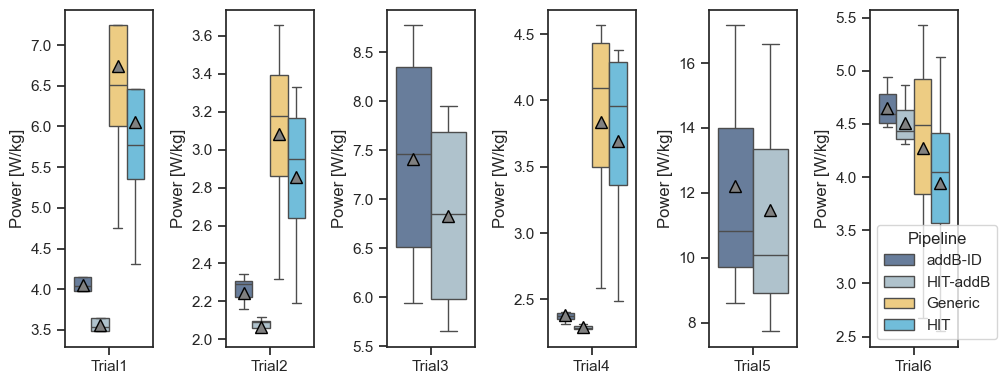

In [64]:
fig = plt.figure(figsize=(10,4))
for t in range(1,7):
    ax = plt.subplot(1,6,t)
    addB_ik_ = pd.DataFrame({key:addB_ik[key] for key in [f"Trial{t}"]})
    HIT_ = pd.DataFrame({key:HIT[key] for key in [f"Trial{t}"]})
    HIT_addB_id_ =pd.DataFrame({key:HIT_addB_id[key] for key in [f"Trial{t}"]})
    addB_id_ = pd.DataFrame({key:addB_id[key] for key in [f"Trial{t}"]})
    addB_ik_['Pipeline'] = 'Generic'
    HIT_['Pipeline'] = 'HIT'
    HIT_addB_id_['Pipeline'] = 'HIT-addB'
    addB_id_['Pipeline'] = 'addB-ID'
    df = pd.concat([addB_id_, HIT_addB_id_, addB_ik_, HIT_])
    df = df.melt(id_vars='Pipeline')
    # Make the plot but use multiple colors

    sns.boxplot(y='value', data=df, x="variable", hue='Pipeline', showfliers=False, showmeans = True,meanprops={'marker':'^','markerfacecolor':'grey','markeredgecolor':'black','markersize':'8'})
    plt.xlabel('')
    if t != 6:
        try:
            ax.get_legend().remove()
        except:
            pass
    plt.ylabel('Power [W/kg]')
plt.tight_layout()
    # save as pdf
plt.savefig('plots/power_comparison_id.pdf', bbox_inches='tight')

In [46]:
df

,Pipeline,variable,value
0,addB-ID,Trial2,2.557925
1,addB-ID,Trial2,2.557925
2,addB-ID,Trial2,2.557925
3,addB-ID,Trial2,2.557925
4,addB-ID,Trial2,2.557925
...,...,...,...
107,Generic,Trial2,2.199407
108,HIT,Trial2,2.780026
109,HIT,Trial2,3.125743
110,HIT,Trial2,3.346887


In [131]:
(addB_id_.iloc[:,2].mean()-HIT_addB_id_.iloc[:,2].mean())/addB_id_.iloc[:,2].mean()

0.05314172327571094

In [130]:
addB_id_.iloc[:,2].mean()

3.086641538226812

In [153]:
collfunc = lambda x: np.mean(np.abs(x))
pipelines = [['HIT', 'body']]#, ['InsideHumans', 'skin']] #['HIT', 'scan']]
participants = ['P02','P04','P05','P06']
mass_list = [73.35, 89.36, 87.63,44.91]
result_df = pd.DataFrame(columns=['participant', 'trial','pipeline', 'dimension', 'value','value_rel'])
for participant,mass in zip(participants, mass_list):
    for trial in range(1,7):
        if participant == "P03" or (participant == 'P06' and trial == 5) or (participant == 'P01' and trial > 2) or (participant == 'P03' and trial == 2):
            continue
        for pipeline in pipelines:
            name, model = pipeline
            name2 = name+model
            id1 = pd.read_csv(f"results/{participant}/gait/ID_results/Trial{trial}_{name}_{model}.sto", sep='\t', skiprows=6)
            try:
                id3 = pd.read_csv(f"results/{participant}/gait/ID_results/Trial{trial}_generic_male_body.sto", sep='\t', skiprows=6)
            except:
                id3 = pd.read_csv(f"results/{participant}/gait/ID_results/Trial{trial}_generic_female_body.sto", sep='\t', skiprows=6)
            id2 = pd.read_csv(f"results/{participant}/gait/ID_results/Trial{trial}_ignore_physics.sto", sep='\t', skiprows=6)
            for dim in ['pelvis_tx_force', 'pelvis_ty_force', 'pelvis_tz_force', 'pelvis_tilt_moment', 'pelvis_list_moment', 'pelvis_rotation_moment']:
                result_df.loc[len(result_df)] = [participant, trial, name, dim, collfunc(id1[dim])/mass/9.81, (collfunc(id2[dim])-collfunc(id1[dim]))/collfunc(id2[dim])]
                result_df.loc[len(result_df)] = [participant, trial, "SMPL-generic", dim, collfunc(id3[dim])/mass/9.81, (collfunc(id2[dim])-collfunc(id1[dim]))/collfunc(id2[dim])]

            #result_df.loc[len(result_df)] = [participant, trial, name, 'f_norm', np.mean(np.linalg.norm([id1['pelvis_tx_force'], id1['pelvis_ty_force'], id1['pelvis_tz_force']], axis=0))/mass/9.81, 0]
            #result_df.loc[len(result_df)] = [participant, trial, name, 'm_norm', np.mean(np.linalg.norm([id1['pelvis_tilt_moment'], id1['pelvis_list_moment'], id1['pelvis_rotation_moment']], axis=0))/mass/9.81, 0]
        for dim in ['pelvis_tx_force', 'pelvis_ty_force', 'pelvis_tz_force', 'pelvis_tilt_moment', 'pelvis_list_moment', 'pelvis_rotation_moment']:
            result_df.loc[len(result_df)] = [participant, trial, 'addB-IK', dim, collfunc(id2[dim])/mass/9.81, 0]
        #result_df.loc[len(result_df)] = [participant, trial, 'addB-IK', 'f_norm', np.mean(np.linalg.norm([id2[dim] for dim in ['pelvis_tx_force', 'pelvis_ty_force', 'pelvis_tz_force']], axis=0))/mass/9.81, 0]
        #result_df.loc[len(result_df)] = [participant, trial, 'addB-IK', 'm_norm', np.mean(np.linalg.norm([id2[dim] for dim in ['pelvis_tilt_moment', 'pelvis_list_moment', 'pelvis_rotation_moment']], axis=0))/mass/9.81, 0]
result_df

,participant,trial,pipeline,dimension,value,value_rel
0,P02,1,HIT,pelvis_tx_force,0.049011,0.170298
1,P02,1,SMPL-generic,pelvis_tx_force,0.052766,0.170298
2,P02,1,HIT,pelvis_ty_force,0.027601,0.225625
3,P02,1,SMPL-generic,pelvis_ty_force,0.031532,0.225625
4,P02,1,HIT,pelvis_tz_force,0.026997,0.177209
...,...,...,...,...,...,...
409,P06,6,addB-IK,pelvis_ty_force,0.032797,0.000000
410,P06,6,addB-IK,pelvis_tz_force,0.032581,0.000000
411,P06,6,addB-IK,pelvis_tilt_moment,0.023650,0.000000
412,P06,6,addB-IK,pelvis_list_moment,0.016451,0.000000


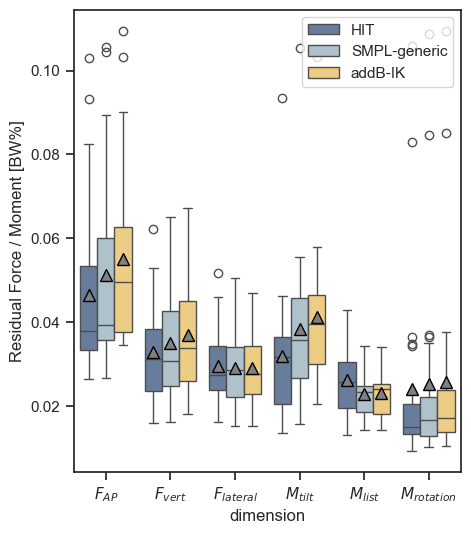

In [160]:
import seaborn as sns
plt.figure(figsize=(5,6))

sns.boxplot(x='dimension', y='value', data=result_df, hue='pipeline',showmeans = True,meanprops={'marker':'^','markerfacecolor':'grey','markeredgecolor':'black','markersize':'8'})
# Make the x labels vertical
plt.ylabel('Residual Force / Moment [BW%]')
# out the legend to the top right
plt.legend(loc='upper right')
# rename the x ticks
plt.xticks(labels=["$F_{AP}$", "$F_{vert}$", "$F_{lateral}$", "$M_{tilt}$", "$M_{list}$", "$M_{rotation}$"], ticks=[0, 1, 2, 3, 4, 5])
# Save the plot
plt.savefig('plots/force_moment_w_smpl.pdf', bbox_inches='tight')

trial=1, Model=HIT: 0.12
trial=1, Model=SMPL: 0.09
trial=2, Model=HIT: 0.08
trial=2, Model=SMPL: 0.06
trial=3, Model=HIT: 0.10
trial=3, Model=SMPL: 0.08
trial=4, Model=HIT: 0.05
trial=4, Model=SMPL: 0.03
trial=5, Model=HIT: 0.08
trial=5, Model=SMPL: 0.07
trial=6, Model=HIT: 0.09
trial=6, Model=SMPL: 0.07
Model=HIT: 0.087
Model=SMPL: 0.067
trial=1: 0.107
trial=2: 0.071
trial=3: 0.093
trial=4: 0.041
trial=5: 0.071
trial=6: 0.078
Overall: 0.077


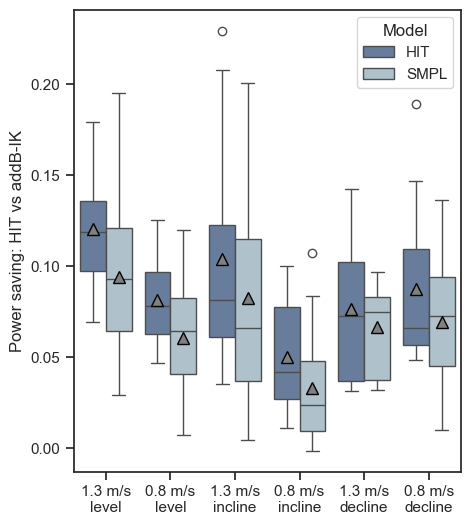

In [78]:
# Power plots 
df = pd.DataFrame(columns=['participant', 'trial', 'Work', 'value','Model'])
participants = ['P02','P04','P05','P06']
mass_list = [73.35, 89.36, 87.63,44.91]
for participant,mass in zip(participants, mass_list):
    for trial in [1,2,3,4,5,6]:
        if participant in ['Pü01','P03'] or (participant == 'P06' and trial == 5) or (participant == 'P01' and trial > 2):
            continue
        ik_data = pd.read_csv(f"results/{participant}/gait/addB-ignore_phys/IK/Trial{trial}.mot", sep='\t', skiprows=10)
        id1 = pd.read_csv(f"results/{participant}/gait/ID_results/Trial{trial}_HIT_body.sto", sep='\t', skiprows=6)
        try:
            id3 = pd.read_csv(f"results/{participant}/gait/ID_results/Trial{trial}_generic_male_body.sto", sep='\t', skiprows=6)
        except:
            id3 = pd.read_csv(f"results/{participant}/gait/ID_results/Trial{trial}_generic_female_body.sto", sep='\t', skiprows=6)
        id2 = pd.read_csv(f"results/{participant}/gait/ID_results//Trial{trial}_ignore_physics.sto", sep='\t', skiprows=6)
        pow1 = np.zeros(ik_data.shape)
        pow2 = np.zeros(ik_data.shape)#
        pow3 = np.zeros(ik_data.shape)
        for i, col_a in enumerate(ik_data.columns):
            ik_data.loc[:,col_a] = np.gradient(ik_data[col_a]) * 100
            if col_a in ['time', 'Time', 'Frame#'] or col_a.startswith('pelvis'):
                continue
            try:
                pow1[:,i] = id1[col_a+'_moment'] * ik_data[col_a] / len(ik_data)
                pow2[:,i] = id2[col_a+'_moment'] * ik_data[col_a] / len(ik_data)  
                pow3[:,i] = id3[col_a+'_moment'] * ik_data[col_a] / len(ik_data)
            except:
                pow1[:,i] = id1[col_a+'_force'] * ik_data[col_a] / len(ik_data) 
                pow2[:,i] = id2[col_a+'_force'] * ik_data[col_a] / len(ik_data)
                pow3[:,i] = id3[col_a+'_force'] * ik_data[col_a] / len(ik_data)
                print(col_a)
        #df.loc[len(df)] = [participant, trial, 'pos_ih', np.sum(pow1[pow1>0])/mass]
        #df.loc[len(df)] = [participant, trial, 'neg_ih', -np.sum(pow1[pow1<0])/mass]
        #df.loc[len(df)] = [participant, trial, 'pos_addb', np.sum(pow2[pow2>0])/mass]
        #df.loc[len(df)] = [participant, trial, 'neg_addb', -np.sum(pow2[pow2<0])/mass]
        df.loc[len(df)] = [participant, trial, 'Negative', -1+np.sum(pow2[pow2>0])/np.sum(pow1[pow1>0]),'HIT']
        df.loc[len(df)] = [participant, trial, 'Positive', -1+np.sum(pow2[pow2<0])/np.sum(pow1[pow1<0]),'HIT']
        #df.loc[len(df)] = [participant, trial, 'total_ih', np.sum(np.abs(pow1))/mass]
        #df.loc[len(df)] = [participant, trial, 'total_addb', np.sum(np.abs(pow2))/mass]
        df.loc[len(df)] = [participant, trial, 'Overall', -1+np.sum(np.abs(pow2))/np.sum(np.abs(pow1)),'HIT']
        df.loc[len(df)] = [participant, trial, 'Negative', -1+np.sum(pow3[pow3>0])/np.sum(pow1[pow1>0]),'SMPL']
        df.loc[len(df)] = [participant, trial, 'Positive', -1+np.sum(pow3[pow3<0])/np.sum(pow1[pow1<0]),'SMPL']
        #df.loc[len(df)] = [participant, trial, 'total_ih', np.sum(np.abs(pow1))/mass]
        #df.loc[len(df)] = [participant, trial, 'total_addb', np.sum(np.abs(pow2))/mass]
        df.loc[len(df)] = [participant, trial, 'Overall', -1+np.sum(np.abs(pow3))/np.sum(np.abs(pow1)),'SMPL']

df2 = df.copy()
x = 'trial'
hue = 'Model'
plt.figure(figsize=(5,6))
sns.boxplot(df2, x=x, y='value', hue=hue,showmeans=True,meanprops={'marker':'^','markerfacecolor':'grey','markeredgecolor':'black','markersize':'8'})
# Y grid
# Plot the mean for every column
# Rename the xticks
plt.xticks(labels=["1.3 m/s\nlevel", "0.8 m/s\nlevel", "1.3 m/s\nincline", "0.8 m/s\nincline", "1.3 m/s\ndecline", "0.8 m/s\ndecline"], ticks=[0, 1, 2, 3, 4, 5])
plt.ylabel('Power saving: HIT vs addB-IK')
#plt.xlabel('Trial')
# print the mean for every column x and per x and hue
# Get a list of unique values in the column
for value_ in df2[x].unique():
    for hue_ in df2[hue].unique():
        print(f'{x}={value_}, {hue}={hue_}: {df2[(df2[x] == value_) & (df2[hue] == hue_)].value.mean():.2f}')
for hue_ in df2[hue].unique():
    print(f'{hue}={hue_}: {df2[df2[hue] == hue_].value.mean():.3f}')
for value_ in df2[x].unique():
    print(f'{x}={value_}: {df2[df2[x] == value_].value.mean():.3f}')
# Print the mean for every column
print(f'Overall: {df2.value.mean():.3f}')
# Remove the x title
plt.xlabel('')

# save as pdf
os.makedirs('plots', exist_ok=True)
plt.savefig('plots/power_saving_w_smpl.pdf', bbox_inches='tight')
# Print the mean for every column

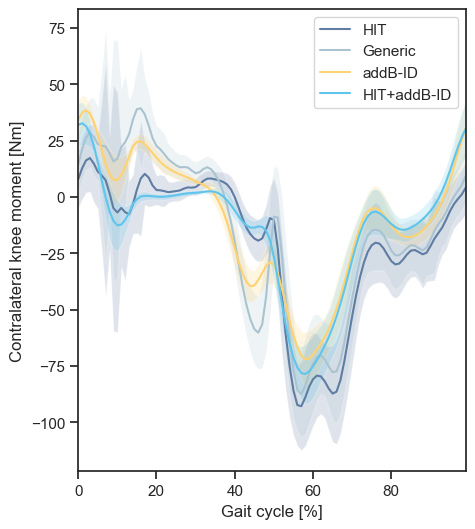

In [83]:
p = 'P04'
trial = 3
mass = 44.91

grf_path = f"/Users/markusgambietz/PhD/01_Python_Projects/mrigait_empkins/data/{p}/gait/Trial{trial}_filtered.mot"
grf = pd.read_csv(grf_path, sep='\t', skiprows=5)

grf_y = grf['ground_force_vy'].to_numpy().copy()
grf_y[grf_y<30] = 0
grf_y[grf_y>0] = 1

# Find all rising edges
rising_edges = np.where(np.diff(grf_y) == 1)[0]
# Plot the data from the first rising edge to the next falling edge

grf_y = grf['ground_force_vy'].to_numpy()
gc_list = []    
for i in range(len(rising_edges)-1):
    start = rising_edges[i]
    end = rising_edges[i+1]
    gc_list.append((start, end))

# plot the lengths of each gaait cycle
plt.figure(figsize=(5,6))
mean_gc_len = np.mean([end-start for start, end in gc_list])
std_gc_len = np.std([end-start for start, end in gc_list])
gc_filtered = []
for start, end in gc_list:
    if abs(end-start-mean_gc_len) < std_gc_len:
        gc_filtered.append((start, end))

# loadID 
id1 = pd.read_csv(f"results/{p}/gait/ID_results/Trial{trial}_HIT_body.sto", sep='\t', skiprows=6)
dim = "hip_flexion_r_moment"
# Grab all gait cycles
gc_list = []
for gc in gc_filtered:
    start, end = gc
    # Get the index of the first and last gait cycle
    id1_gc = id1[dim].iloc[start:end].to_numpy().copy()
    # interpolate to 100 points
    id1_gc = np.interp(np.linspace(0, len(id1_gc)-1, 100), np.arange(len(id1_gc)), id1_gc)
    gc_list.append(id1_gc)
mean_id1 = np.mean(gc_list, axis=0)
std_id1 = np.std(gc_list, axis=0)
# Plot the data
plt.plot(mean_id1, label='HIT')
plt.fill_between(np.arange(len(mean_id1)), mean_id1-std_id1, mean_id1+std_id1, alpha=0.2)

id1 = pd.read_csv(f"results/{p}/gait/ID_results/Trial{trial}_generic_male_body.sto", sep='\t', skiprows=6)
gc_list = []

for gc in gc_filtered:
    start, end = gc
    # Get the index of the first and last gait cycle
    id1_gc = id1[dim].iloc[start:end].to_numpy().copy()
    # interpolate to 100 points
    id1_gc = np.interp(np.linspace(0, len(id1_gc)-1, 100), np.arange(len(id1_gc)), id1_gc)
    gc_list.append(id1_gc)
mean_id1 = np.mean(gc_list, axis=0)
std_id1 = np.std(gc_list, axis=0)
#plt.plot(mean_id1, label='SMPL-generic')
#plt.fill_between(np.arange(len(mean_id1)), mean_id1-std_id1, mean_id1+std_id1, alpha=0.2)


id1 = pd.read_csv(f"results/{p}/gait/ID_results/Trial{trial}_ignore_physics.sto", sep='\t', skiprows=6)
gc_list = []

for gc in gc_filtered:
    start, end = gc
    # Get the index of the first and last gait cycle
    id1_gc = id1[dim].iloc[start:end].to_numpy().copy()
    # interpolate to 100 points
    id1_gc = np.interp(np.linspace(0, len(id1_gc)-1, 100), np.arange(len(id1_gc)), id1_gc)
    gc_list.append(id1_gc)
mean_id1 = np.mean(gc_list, axis=0)
std_id1 = np.std(gc_list, axis=0)
plt.plot(mean_id1, label='Generic')
plt.fill_between(np.arange(len(mean_id1)), mean_id1-std_id1, mean_id1+std_id1, alpha=0.2)

gc_list = []
for i in range(15):
    try:
        path = f"/Users/markusgambietz/PhD/01_Python_Projects/mrigait_empkins/results/{p}/gait/addB-with_phys/generic/ID/Trial{trial}_segment_{i}_id.sto"
        df = pd.read_csv(path, sep='\t', skiprows=10)
    except:
        continue
    idx_0 = i * 2000
    for gc in gc_filtered:
        start, end = gc
        if end > idx_0 + 2000 or start < idx_0:
            continue
        id1_gc = df[dim].iloc[start-idx_0:end-idx_0].to_numpy().copy()
    try:
        id1_gc = np.interp(np.linspace(0, len(id1_gc)-1, 100), np.arange(len(id1_gc)), id1_gc)
        gc_list.append(id1_gc)
    except:
        continue
mean_id1 = np.mean(gc_list, axis=0)
std_id1 = np.std(gc_list, axis=0)
plt.plot(mean_id1, label='addB-ID')
plt.fill_between(np.arange(len(mean_id1)), mean_id1-std_id1, mean_id1+std_id1, alpha=0.2)
plt.legend()

gc_list = []
for i in range(15):
    try:
        path = f"/Users/markusgambietz/PhD/01_Python_Projects/mrigait_empkins/results/{p}/gait/addB-with_phys/HIT/ID/Trial{trial}_segment_{i}_id.sto"
        df = pd.read_csv(path, sep='\t', skiprows=10)
    except:
        continue
    idx_0 = i * 2000
    for gc in gc_filtered:
        start, end = gc
        if end > idx_0 + 2000 or start < idx_0:
            continue
        id1_gc = df[dim].iloc[start-idx_0:end-idx_0].to_numpy().copy()
    try:
        id1_gc = np.interp(np.linspace(0, len(id1_gc)-1, 100), np.arange(len(id1_gc)), id1_gc)
        gc_list.append(id1_gc)
    except:
        continue
mean_id1 = np.mean(gc_list, axis=0)
std_id1 = np.std(gc_list, axis=0)
plt.plot(mean_id1, label='HIT+addB-ID')
plt.fill_between(np.arange(len(mean_id1)), mean_id1-std_id1, mean_id1+std_id1, alpha=0.2)
plt.legend()

plt.xlabel('Gait cycle [%]')
plt.ylabel('Contralateral knee moment [Nm]')
plt.xlim(0, 99)

# save as pdf
plt.savefig(f'plots/{dim}.pdf', bbox_inches='tight')

/opt/homebrew/Caskroom/miniforge/base/envs/osim_10/lib/python3.10/site-packages/numpy/core/fromnumeric.py:3432: RuntimeWarning: Mean of empty slice.
  return _methods._mean(a, axis=axis, dtype=dtype,
/opt/homebrew/Caskroom/miniforge/base/envs/osim_10/lib/python3.10/site-packages/numpy/core/_methods.py:190: RuntimeWarning: invalid value encountered in double_scalars
  ret = ret.dtype.type(ret / rcount)
/opt/homebrew/Caskroom/miniforge/base/envs/osim_10/lib/python3.10/site-packages/numpy/core/_methods.py:265: RuntimeWarning: Degrees of freedom <= 0 for slice
  ret = _var(a, axis=axis, dtype=dtype, out=out, ddof=ddof,
/opt/homebrew/Caskroom/miniforge/base/envs/osim_10/lib/python3.10/site-packages/numpy/core/_methods.py:223: RuntimeWarning: invalid value encountered in divide
  arrmean = um.true_divide(arrmean, div, out=arrmean, casting='unsafe',
/opt/homebrew/Caskroom/miniforge/base/envs/osim_10/lib/python3.10/site-packages/numpy/core/_methods.py:257: RuntimeWarning: invalid value encount

TypeError: object of type 'numpy.float64' has no len()

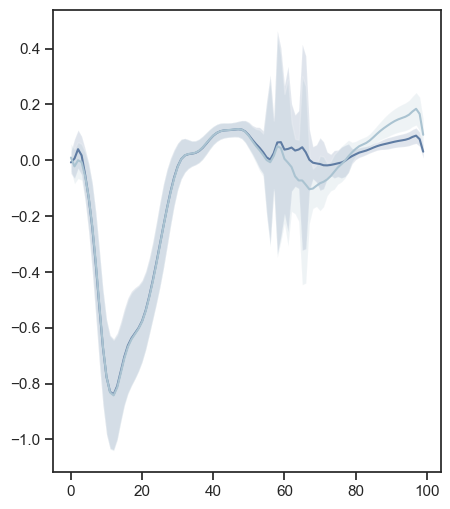

In [ ]:
p = 'P04'
trial = 3
mass = 44.91

grf_path = f"/Users/markusgambietz/PhD/01_Python_Projects/mrigait_empkins/data/{p}/gait/Trial{trial}_filtered.mot"
grf = pd.read_csv(grf_path, sep='\t', skiprows=5)

grf_y = grf['1_ground_force_vy'].to_numpy().copy()
grf_y[grf_y<30] = 0
grf_y[grf_y>0] = 1

# Find all rising edges
rising_edges = np.where(np.diff(grf_y) == 1)[0]
# Plot the data from the first rising edge to the next falling edge

grf_y = grf['1_ground_force_vy'].to_numpy()
gc_list = []    
for i in range(len(rising_edges)-1):
    start = rising_edges[i]
    end = rising_edges[i+1]
    gc_list.append((start, end))

# plot the lengths of each gaait cycle
plt.figure(figsize=(5,6))
mean_gc_len = np.mean([end-start for start, end in gc_list])
std_gc_len = np.std([end-start for start, end in gc_list])
gc_filtered = []
for start, end in gc_list:
    if abs(end-start-mean_gc_len) < std_gc_len:
        gc_filtered.append((start, end))

# loadID 
id1 = pd.read_csv(f"results/{p}/gait/ID_results/Trial{trial}_HIT_body.sto", sep='\t', skiprows=6)
id_1_ik = pd.read_csv(f"results/{p}/gait/addB-ignore_phys/IK/Trial{trial}_filtered.mot", sep='\t', skiprows=10)
dim = "knee_angle_r_moment"
dim_ik = "knee_angle_r"
# Grab all gait cycles
gc_list = []

for gc in gc_filtered:
    start, end = gc
    # Get the index of the first and last gait cycle
    id1_gc = id1[dim].iloc[start:end].to_numpy().copy()
    id1_ik_gc = id_1_ik[dim_ik].iloc[start:end].to_numpy().copy()
    # interpolate to 100 points
    id1_gc = np.interp(np.linspace(0, len(id1_gc)-1, 100), np.arange(len(id1_gc)), id1_gc)
    id1_ik_gc = np.interp(np.linspace(0, len(id1_ik_gc)-1, 100), np.arange(len(id1_ik_gc)), id1_ik_gc)
    gc_list.append(id1_gc*id1_ik_gc/100)
mean_id1 = np.mean(gc_list, axis=0)
std_id1 = np.std(gc_list, axis=0)
# Plot the data
plt.plot(mean_id1, label='HIT')
plt.fill_between(np.arange(len(mean_id1)), mean_id1-std_id1, mean_id1+std_id1, alpha=0.2)

gc_list = []
id1 = pd.read_csv(f"results/{p}/gait/ID_results/Trial{trial}_generic_male_body.sto", sep='\t', skiprows=6)
for gc in gc_filtered:
    start, end = gc
    # Get the index of the first and last gait cycle
    id1_gc = id1[dim].iloc[start:end].to_numpy().copy()
    id1_ik_gc = id_1_ik[dim_ik].iloc[start:end].to_numpy().copy()
    # interpolate to 100 points
    id1_gc = np.interp(np.linspace(0, len(id1_gc)-1, 100), np.arange(len(id1_gc)), id1_gc)
    id1_ik_gc = np.interp(np.linspace(0, len(id1_ik_gc)-1, 100), np.arange(len(id1_ik_gc)), id1_ik_gc)
    gc_list.append(id1_gc*id1_ik_gc/100)
mean_id1 = np.mean(gc_list, axis=0)
stgd_id1 = np.std(gc_list, axis=0)
#plt.plot(mean_id1, label='SMPL-generic')
#plt.fill_between(np.arange(len(mean_id1)), mean_id1-std_id1, mean_id1+std_id1, alpha=0.2)


gc_list = []
id1 = pd.read_csv(f"results/{p}/gait/ID_results/Trial{trial}_ignore_physics.sto", sep='\t', skiprows=6)
for gc in gc_filtered:
    start, end = gc
    # Get the index of the first and last gait cycle
    id1_gc = id1[dim].iloc[start:end].to_numpy().copy()
    id1_ik_gc = id_1_ik[dim_ik].iloc[start:end].to_numpy().copy()
    # interpolate to 100 points
    id1_gc = np.interp(np.linspace(0, len(id1_gc)-1, 100), np.arange(len(id1_gc)), id1_gc)
    id1_ik_gc = np.interp(np.linspace(0, len(id1_ik_gc)-1, 100), np.arange(len(id1_ik_gc)), id1_ik_gc)
    gc_list.append(id1_gc*id1_ik_gc/100)
mean_id1 = np.mean(gc_list, axis=0)
std_id1 = np.std(gc_list, axis=0)
plt.plot(mean_id1, label='Generic')
plt.fill_between(np.arange(len(mean_id1)), mean_id1-std_id1, mean_id1+std_id1, alpha=0.2)

gc_list = []
for i in range(15):
    try:
        path = f"/Users/markusgambietz/PhD/01_Python_Projects/mrigait_empkins/results/{p}/gait/addB-with_phys/generic/ID/Trial{trial}_segment_{i}_id.sto"
        df = pd.read_csv(path, sep='\t', skiprows=10)
        path2 = f"/Users/markusgambietz/PhD/01_Python_Projects/mrigait_empkins/results/{p}/gait/addB-with_phys/generic/IK/Trial{trial}_segment_{i}_id.mot"
        df2 = pd.read_csv(path2, sep='\t', skiprows=10)
    except:
        continue
    idx_0 = i * 2000
    for gc in gc_filtered:
        start, end = gc
        if end > idx_0 + 2000 or start < idx_0:
            continue
        id1_gc = df[dim].iloc[start-idx_0:end-idx_0].to_numpy().copy()
        id1_ik_gc = df2[dim_ik].iloc[start-idx_0:end-idx_0].to_numpy().copy()
    try:
        id1_gc = np.interp(np.linspace(0, len(id1_gc)-1, 100), np.arange(len(id1_gc)), id1_gc)
        id1_ik_gc = np.interp(np.linspace(0, len(id1_ik_gc)-1, 100), np.arange(len(id1_ik_gc)), id1_ik_gc)
        gc_list.append(id1_gc*id1_ik_gc/100)
    except:
        continue
mean_id1 = np.mean(gc_list, axis=0)
std_id1 = np.std(gc_list, axis=0)
plt.plot(mean_id1, label='addB-ID')
plt.fill_between(np.arange(len(mean_id1)), mean_id1-std_id1, mean_id1+std_id1, alpha=0.2)
plt.legend()

gc_list = []
for i in range(15):
    try:
        path = f"/Users/markusgambietz/PhD/01_Python_Projects/mrigait_empkins/results/{p}/gait/addB-with_phys/HIT/ID/Trial{trial}_segment_{i}_id.sto"
        df = pd.read_csv(path, sep='\t', skiprows=10)
    except:
        continue
    idx_0 = i * 2000
    for gc in gc_filtered:
        start, end = gc
        if end > idx_0 + 2000 or start < idx_0:
            continue
        id1_gc = df[dim].iloc[start-idx_0:end-idx_0].to_numpy().copy()
    try:
        id1_gc = np.interp(np.linspace(0, len(id1_gc)-1, 100), np.arange(len(id1_gc)), id1_gc)
        gc_list.append(id1_gc)
    except:
        continue
#mean_id1 = np.mean(gc_list, axis=0)
#std_id1 = np.std(gc_list, axis=0)
#plt.plot(mean_id1, label='HIT+addB-ID')
#plt.fill_between(np.arange(len(mean_id1)), mean_id1-std_id1, mean_id1+std_id1, alpha=0.2)
plt.legend()
#
plt.xlabel('Gait cycle [%]')
plt.ylabel(f'{dim_ik} power [W/kg]')
plt.xlim(0, 99)
#
# save as pdf
plt.savefig(f'plots/power_{dim}.pdf', bbox_inches='tight')
plt.grid()

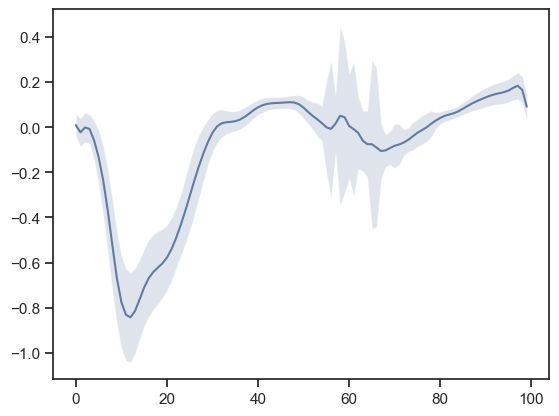

In [77]:
gc_list = []
id1 = pd.read_csv(f"results/{p}/gait/ID_results/Trial{trial}_generic_male_body.sto", sep='\t', skiprows=6)
for gc in gc_filtered:
    start, end = gc
    # Get the index of the first and last gait cycle
    id1_gc = id1[dim].iloc[start:end].to_numpy().copy()
    id1_ik_gc = id_1_ik[dim_ik].iloc[start:end].to_numpy().copy()
    # interpolate to 100 points
    id1_gc = np.interp(np.linspace(0, len(id1_gc)-1, 100), np.arange(len(id1_gc)), id1_gc)
    id1_ik_gc = np.interp(np.linspace(0, len(id1_ik_gc)-1, 100), np.arange(len(id1_ik_gc)), id1_ik_gc)
    gc_list.append(id1_gc*id1_ik_gc/100)
mean_id1 = np.mean(gc_list, axis=0)
stgd_id1 = np.std(gc_list, axis=0)
plt.plot(mean_id1, label='SMPL-generic')
plt.fill_between(np.arange(len(mean_id1)), mean_id1-std_id1, mean_id1+std_id1, alpha=0.2)

In [213]:

end

29979

In [73]:
id_1_ik

,time,pelvis_tilt,pelvis_list,pelvis_rotation,pelvis_tx,pelvis_ty,pelvis_tz,hip_flexion_r,hip_adduction_r,hip_rotation_r,...,pro_sup_r,wrist_flex_r,wrist_dev_r,arm_flex_l,arm_add_l,arm_rot_l,elbow_flex_l,pro_sup_l,wrist_flex_l,wrist_dev_l
0,0.01,0.006591,0.035082,0.014449,0.013835,0.998108,-0.015897,0.004132,-0.115373,-0.208311,...,1.5708,0.0,0.0,0.023992,-0.172568,0.198781,0.481374,1.570800,0.0,0.0
1,0.02,0.008808,0.032534,0.015015,0.013647,0.998430,-0.015757,-0.003243,-0.110130,-0.202075,...,1.5708,0.0,0.0,0.024649,-0.172332,0.197722,0.479943,1.570800,0.0,0.0
2,0.03,0.010135,0.030976,0.015290,0.013432,0.998634,-0.015630,-0.007721,-0.106793,-0.197708,...,1.5708,0.0,0.0,0.025249,-0.172247,0.197148,0.478675,1.570800,0.0,0.0
3,0.04,0.010425,0.030559,0.015244,0.013180,0.998701,-0.015516,-0.008816,-0.105667,-0.195572,...,1.5708,0.0,0.0,0.025808,-0.172337,0.197196,0.477672,1.570800,0.0,0.0
4,0.05,0.010106,0.030807,0.015036,0.012900,0.998687,-0.015411,-0.007894,-0.105842,-0.194870,...,1.5708,0.0,0.0,0.026395,-0.172531,0.197743,0.476944,1.570800,0.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
29992,299.93,-0.174157,0.115341,-0.008351,0.112715,0.949162,0.004763,-0.009382,-0.189871,-0.115822,...,1.5708,0.0,0.0,-0.083216,-0.195949,-0.188604,0.470200,1.540376,0.0,0.0
29993,299.94,-0.175511,0.116453,-0.003575,0.113986,0.951512,0.002381,0.018883,-0.201472,-0.120757,...,1.5708,0.0,0.0,-0.079311,-0.199241,-0.174168,0.478516,1.536971,0.0,0.0
29994,299.95,-0.175609,0.116225,0.001173,0.114961,0.954179,0.000088,0.047555,-0.211419,-0.124516,...,1.5708,0.0,0.0,-0.074703,-0.202309,-0.160248,0.487656,1.534947,0.0,0.0
29995,299.96,-0.174674,0.114108,0.005690,0.115707,0.957068,-0.002076,0.076114,-0.218925,-0.127481,...,1.5708,0.0,0.0,-0.069690,-0.204915,-0.147525,0.497527,1.533394,0.0,0.0
